# Exercise 2.2 | Linear Regression using sklearn
Do the following tasks:
- Use your fuel dataset
- Perform univariate (single independent variable, choose the highest correlation)
- Make sure to include the R squared, MSE, and RMSE
- Submit the accomplished Jupyter Notebook file in pdf format and share the link that shows the building of linear regression using sklearn.

Name: Abon, Benedict Aldous A.<br>
Course / Section: CPE 312 / CPE31S3<br>
Date Performed: 8/6/26<br>
Date Finished: 8/6/26<br>
Istructor: Engr. Robin Valenzuela

Setup

In [222]:
# Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

Use Fuel Dataset (MPG (miles per gallon))

In [223]:
# Import df
df = pd.read_csv('auto-mpg.csv')
df.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model year,origin,car name
0,18.0,8,307.0,130,3504,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165,3693,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150,3436,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150,3433,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140,3449,10.5,70,1,ford torino


Describe df

In [224]:
df.shape

(398, 9)

In [225]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    398 non-null    object 
 4   weight        398 non-null    int64  
 5   acceleration  398 non-null    float64
 6   model year    398 non-null    int64  
 7   origin        398 non-null    int64  
 8   car name      398 non-null    object 
dtypes: float64(3), int64(4), object(2)
memory usage: 28.1+ KB


In [226]:
df.describe()

,mpg,cylinders,displacement,weight,acceleration,model year,origin
count,398.000000,398.000000,398.000000,398.000000,398.000000,398.000000,398.000000
mean,23.514573,5.454774,193.425879,2970.424623,15.568090,76.010050,1.572864
std,7.815984,1.701004,104.269838,846.841774,2.757689,3.697627,0.802055
min,9.000000,3.000000,68.000000,1613.000000,8.000000,70.000000,1.000000
25%,17.500000,4.000000,104.250000,2223.750000,13.825000,73.000000,1.000000
50%,23.000000,4.000000,148.500000,2803.500000,15.500000,76.000000,1.000000
75%,29.000000,8.000000,262.000000,3608.000000,17.175000,79.000000,2.000000
max,46.600000,8.000000,455.000000,5140.000000,24.800000,82.000000,3.000000


Data cleaning

In [227]:
# Clean df
df_clean = df.copy()

In [228]:
# Ensure column names do not use spaces
df_clean.columns = df_clean.columns.str.replace(' ', '_')

In [229]:
# Remove duplication rows
df_clean.drop_duplicates(inplace=True)

In [230]:
# Replace '?' values with NaN
df_clean = df_clean.replace('?', np.nan)

In [231]:
# Drop empty rows
df_clean.dropna(inplace=True)

In [232]:
# Convert the 'horsepower' column to integer type
df_clean['horsepower'] = df_clean['horsepower'].astype(int)

In [233]:
# car_name to str
df_clean['car_name'] = df_clean['car_name'].astype(str)

In [234]:
df_clean

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,car_name
0,18.0,8,307.0,130,3504,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165,3693,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150,3436,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150,3433,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140,3449,10.5,70,1,ford torino
...,...,...,...,...,...,...,...,...,...
393,27.0,4,140.0,86,2790,15.6,82,1,ford mustang gl
394,44.0,4,97.0,52,2130,24.6,82,2,vw pickup
395,32.0,4,135.0,84,2295,11.6,82,1,dodge rampage
396,28.0,4,120.0,79,2625,18.6,82,1,ford ranger


/tmp/ipykernel_7288/438797667.py:11: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(loc='upper right')


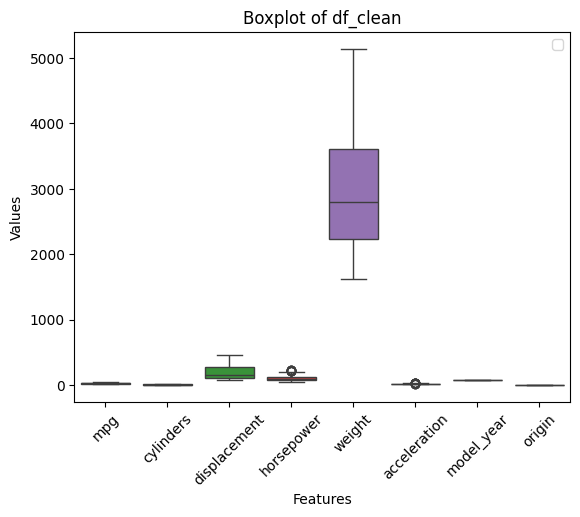

In [235]:
# Check for outliers

# Plot
sns.boxplot(df_clean)

# Properties
plt.title('Boxplot of df_clean')
plt.xlabel('Features')
plt.xticks(rotation=45)
plt.ylabel('Values')
plt.legend(loc='upper right')

plt.show()

Perform univariate (single independent variable, choose the highest correlation)


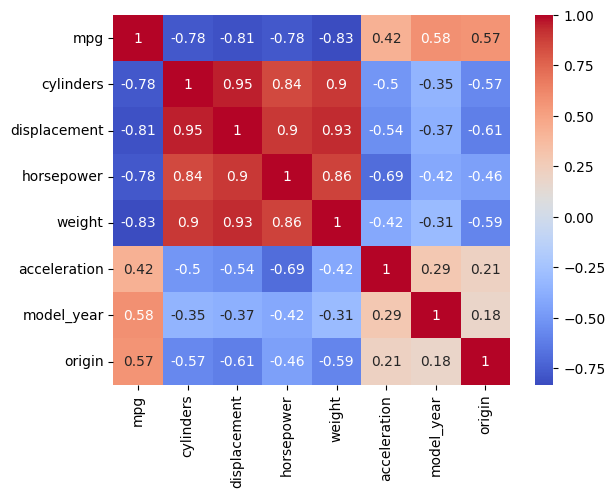

In [236]:
# Correlation
numeric_df_clean = df_clean.select_dtypes(include='number')
sns.heatmap(numeric_df_clean.corr(), annot=True, cmap='coolwarm')
plt.show()

**Highest Correlation Columns (0.93)**<br>
X = weight (independent)<br>
y = displacement (dependent)

In [237]:
# Import sklearn functions
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error

In [238]:
# Extract X and y
X = df_clean[['weight']]
y = df_clean['displacement']

In [239]:
# Split training and testing data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [240]:
# Fitting linear regression to the training set
regressor = LinearRegression()
regressor.fit(X_train, y_train)

LinearRegression()

In [241]:
# Predicting test set results
y_pred = regressor.predict(X_test)
y_pred

array([104.32487544, 173.65252384,  59.82247407,  77.55479338,
       173.08051354, 100.4352054 , 396.85094304, 113.019432  ,
       227.30709002,  67.4874121 , 294.34669722, 189.09680195,
       352.69174785, 102.26563836, 244.00979079, 151.91613243,
       208.77395628, 122.74360711, 159.35226633, 139.90391612,
       177.99980212,  97.57515389,  80.98685518, 254.76358443,
        78.47000986, 113.019432  , 194.70250289, 247.32745053,
        76.98278308, 141.16233878, 361.84391266, 221.12937877,
       266.3181925 , 155.34819423, 364.5895621 ,  82.13087578,
       384.49552055,  97.11754565, 345.14121189, 381.86427317,
       322.71840811,  95.05830857,  80.41484488, 117.02350411,
       386.66915969, 395.59252038, 229.3663271 ,  97.57515389,
       128.57811217,  75.4955563 , 329.12492348, 114.50665878,
       112.90502994, 101.0072157 , 178.22860624, 269.40704812,
       222.38780143, 187.26636899, 125.60365861, 108.78655578,
       420.30336536, 206.82912126, 162.78432813, 192.18

In [242]:
# Coefficient
regressor.coef_

array([0.11440206])

In [243]:
# Intercept
regressor.intercept_

np.float64(-146.1012340577699)

Make sure to include the R squared, MSE, and RMSE


In [244]:
# Evaluate model using R squared
model_score = r2_score(y_test, y_pred)
print(f"R squared: {model_score:.2f}")

R squared: 0.91


In [245]:
# MSE
mse = mean_squared_error(y_test, y_pred)
print(f"MSE: {mse:.2f}")

MSE: 1066.08


In [246]:
# RMSE
rmse = np.sqrt(mse)
print(f"RMSE: {rmse:.2f}")

RMSE: 32.65


Linear Regression Graph

Text(0, 0.5, 'Displacement')

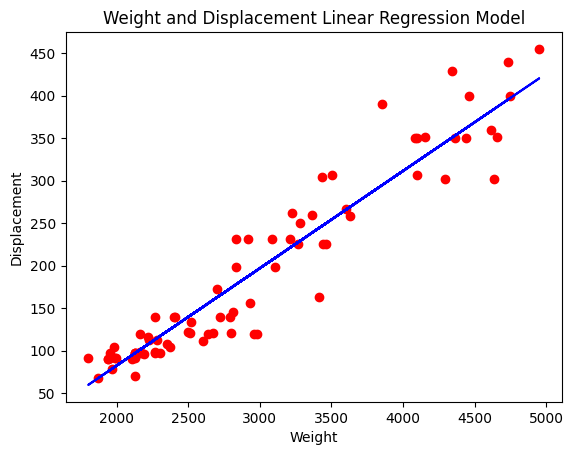

In [249]:
# Plot
plt.scatter(X_test, y_test, color='red')
plt.plot(X_test, y_pred, color='blue')

# Properties
plt.title('Weight and Displacement Linear Regression Model')
plt.xlabel('Weight')
plt.ylabel('Displacement')

Fit Error Graph

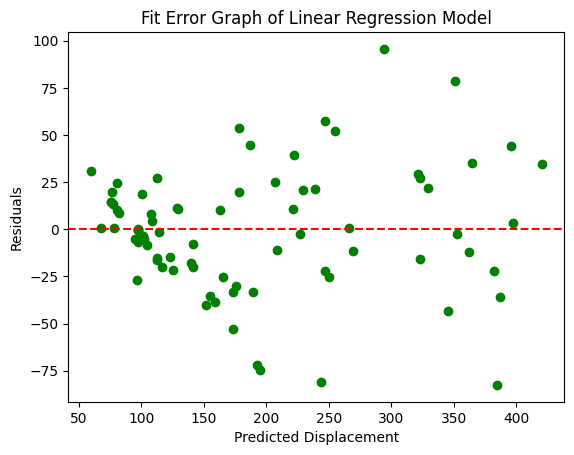

In [251]:
# Residuals
residuals = y_test - y_pred

# Plot
plt.scatter(y_pred, residuals, color='green')
plt.axhline(y=0, color='red', linestyle='--')

# Properties
plt.title('Fit Error Graph of Linear Regression Model')
plt.xlabel('Predicted Displacement')
plt.ylabel('Residuals')

plt.show()